In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

In [33]:
from google.colab import files

uploaded = files.upload()

Saving rfm_segments.csv to rfm_segments (1).csv


In [34]:
rfm = pd.read_csv("rfm_segments.csv")

print("Dataset shape:", rfm.shape)

rfm.head()

Dataset shape: (4338, 10)


,CustomerID,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_score,Segment,Recommended_Action
0,12346.0,326,1,77183.60,1,1,5,115,Lost,Try low-cost reactivation campaigns
1,12347.0,2,7,4310.00,5,5,5,555,Champions,Provide loyalty rewards and early access to ne...
2,12348.0,75,4,1797.24,2,4,4,244,At Risk,Launch win-back emails and personalized discounts
3,12349.0,19,1,1757.55,4,1,4,414,Potential Loyalists,Send welcome offers and second-purchase discounts
4,12350.0,310,1,334.40,1,1,2,112,Lost,Try low-cost reactivation campaigns


In [35]:
print("Columns:")
print(rfm.columns.tolist())

print("\nData types:")
print(rfm.dtypes)

print("\nMissing values:")
print(rfm.isnull().sum())

print("\nDuplicate rows:")
print(rfm.duplicated().sum())

print("\nStatistical summary:")
display(rfm.describe())

Columns:
['CustomerID', 'Recency', 'Frequency', 'Monetary', 'R_score', 'F_score', 'M_score', 'RFM_score', 'Segment', 'Recommended_Action']

Data types:
CustomerID            float64
Recency                 int64
Frequency               int64
Monetary              float64
R_score                 int64
F_score                 int64
M_score                 int64
RFM_score               int64
Segment                object
Recommended_Action     object
dtype: object

Missing values:
CustomerID            0
Recency               0
Frequency             0
Monetary              0
R_score               0
F_score               0
M_score               0
RFM_score             0
Segment               0
Recommended_Action    0
dtype: int64

Duplicate rows:
0

Statistical summary:


,CustomerID,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_score
count,4338.000000,4338.000000,4338.000000,4338.000000,4338.000000,4338.00000,4338.00000,4338.000000
mean,15300.408022,92.536422,4.272015,2048.688081,3.015445,3.00000,3.00000,334.544491
std,1721.808492,100.014169,7.697998,8985.230220,1.414537,1.41454,1.41454,150.063095
min,12346.000000,1.000000,1.000000,3.750000,1.000000,1.00000,1.00000,111.000000
25%,13813.250000,18.000000,1.000000,306.482500,2.000000,2.00000,2.00000,221.000000
50%,15299.500000,51.000000,2.000000,668.570000,3.000000,3.00000,3.00000,333.000000
75%,16778.750000,142.000000,5.000000,1660.597500,4.000000,4.00000,4.00000,454.000000
max,18287.000000,374.000000,209.000000,280206.020000,5.000000,5.00000,5.00000,555.000000


In [36]:
rfm_features = rfm[
    ["Recency", "Frequency", "Monetary"]
].copy()

rfm_features.head()

,Recency,Frequency,Monetary
0,326,1,77183.60
1,2,7,4310.00
2,75,4,1797.24
3,19,1,1757.55
4,310,1,334.40


In [37]:
print(rfm_features.shape)
print(rfm_features.isnull().sum())
print(rfm_features.describe())

(4338, 3)
Recency      0
Frequency    0
Monetary     0
dtype: int64
           Recency    Frequency       Monetary
count  4338.000000  4338.000000    4338.000000
mean     92.536422     4.272015    2048.688081
std     100.014169     7.697998    8985.230220
min       1.000000     1.000000       3.750000
25%      18.000000     1.000000     306.482500
50%      51.000000     2.000000     668.570000
75%     142.000000     5.000000    1660.597500
max     374.000000   209.000000  280206.020000


In [38]:
rfm_features = rfm_features.replace(
    [np.inf, -np.inf],
    np.nan
)

rfm_features = rfm_features.dropna()

rfm_features = rfm_features[
    (rfm_features["Recency"] >= 0) &
    (rfm_features["Frequency"] > 0) &
    (rfm_features["Monetary"] > 0)
]

print("Shape after cleaning:", rfm_features.shape)

Shape after cleaning: (4338, 3)


In [39]:
print("Skewness of RFM features:")

print(rfm_features.skew())

Skewness of RFM features:
Recency       1.246048
Frequency    12.067031
Monetary     19.339368
dtype: float64


In [40]:
rfm_log = rfm_features.copy()

rfm_log["Frequency"] = np.log1p(
    rfm_log["Frequency"]
)

rfm_log["Monetary"] = np.log1p(
    rfm_log["Monetary"]
)

In [41]:
if rfm_features["Recency"].skew() > 1:
    rfm_log["Recency"] = np.log1p(
        rfm_log["Recency"]
    )

In [42]:
print("Before transformation:")
print(rfm_features.skew())

print("\nAfter transformation:")
print(rfm_log.skew())

Before transformation:
Recency       1.246048
Frequency    12.067031
Monetary     19.339368
dtype: float64

After transformation:
Recency     -0.379169
Frequency    1.208652
Monetary     0.396599
dtype: float64


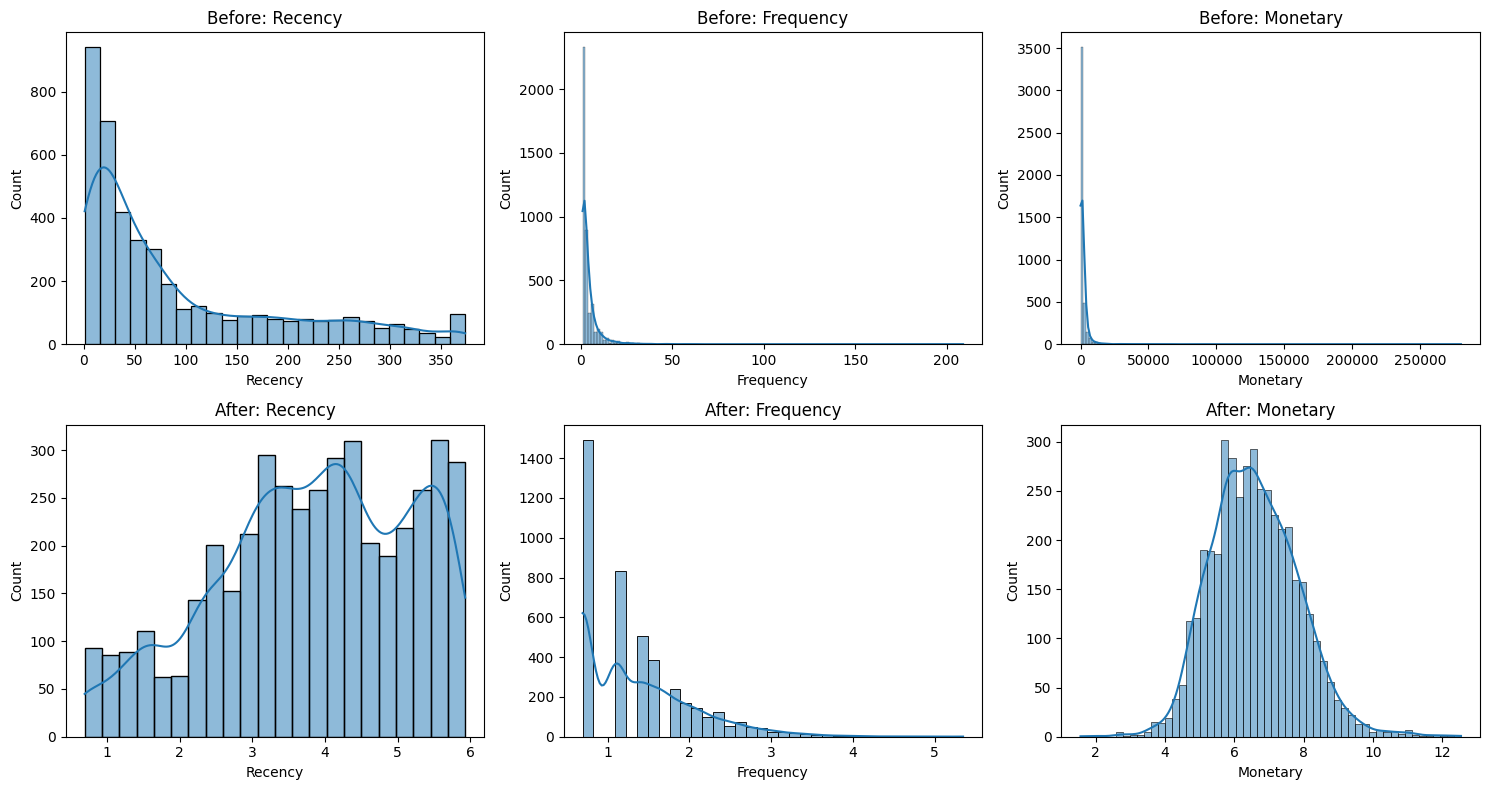

In [43]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, col in enumerate(rfm_features.columns):

    sns.histplot(
        rfm_features[col],
        kde=True,
        ax=axes[0, i]
    )

    axes[0, i].set_title(f"Before: {col}")

    sns.histplot(
        rfm_log[col],
        kde=True,
        ax=axes[1, i]
    )

    axes[1, i].set_title(f"After: {col}")

plt.tight_layout()
plt.show()

In [44]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(rfm_log)

scaled_rfm = pd.DataFrame(
    scaled_data,
    columns=rfm_log.columns,
    index=rfm_log.index
)

scaled_rfm.head()

,Recency,Frequency,Monetary
0,1.461993,-0.955214,3.707716
1,-2.038734,1.074425,1.414903
2,0.373104,0.386304,0.720024
3,-0.623086,-0.955214,0.702287
4,1.424558,-0.955214,-0.614514


In [45]:
print("Means:")
print(scaled_rfm.mean())

print("\nStandard deviations:")
print(scaled_rfm.std())

Means:
Recency     -9.172520e-17
Frequency   -7.206980e-17
Monetary    -3.669008e-16
dtype: float64

Standard deviations:
Recency      1.000115
Frequency    1.000115
Monetary     1.000115
dtype: float64


In [46]:
scaled_rfm.to_csv(
    "scaled_rfm_data.csv",
    index=False
)

print("Scaled RFM data saved successfully!")

Scaled RFM data saved successfully!


In [47]:
from google.colab import files

files.download("scaled_rfm_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [48]:
from sklearn.cluster import KMeans

**ELBOW METHOD**

In [49]:
inertia_values = []

K_range = range(1, 11)

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    kmeans.fit(scaled_rfm)

    inertia_values.append(kmeans.inertia_)

print(inertia_values)

[13013.999999999978, 6483.589425039327, 4869.488628540226, 3939.0493816391686, 3296.70870764254, 2855.764068043103, 2548.820244849556, 2336.3410536103947, 2156.005672521335, 2005.7462362695549]


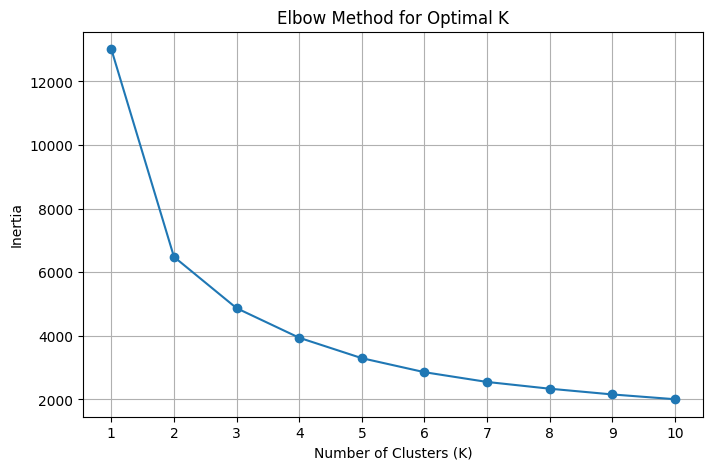

In [50]:
plt.figure(figsize=(8, 5))

plt.plot(
    K_range,
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")

plt.xticks(K_range)
plt.grid(True)

plt.show()

In [51]:
optimal_k = 4  # Example only: replace with your elbow result

print("Selected K:", optimal_k)

Selected K: 4


In [52]:
final_kmeans = KMeans(
    n_clusters=optimal_k,
    init="k-means++",
    n_init=10,
    random_state=42
)

cluster_labels = final_kmeans.fit_predict(scaled_rfm)

In [53]:
clustered_rfm = rfm_features.loc[
    scaled_rfm.index
].copy()

clustered_rfm["Cluster"] = cluster_labels

clustered_rfm.head()

,Recency,Frequency,Monetary,Cluster
0,326,1,77183.60,3
1,2,7,4310.00,0
2,75,4,1797.24,3
3,19,1,1757.55,2
4,310,1,334.40,1


In [54]:
clustered_rfm["Cluster"].value_counts().sort_index()

,count
Cluster,
0,713
1,1622
2,837
3,1166


In [55]:
cluster_summary = clustered_rfm.groupby(
    "Cluster"
).agg(
    Customers=("Recency", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

cluster_summary

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,713,12.17,13.75,8088.02
1,1622,181.51,1.32,341.00
2,837,17.70,2.19,557.32
3,1166,71.64,4.08,1801.78


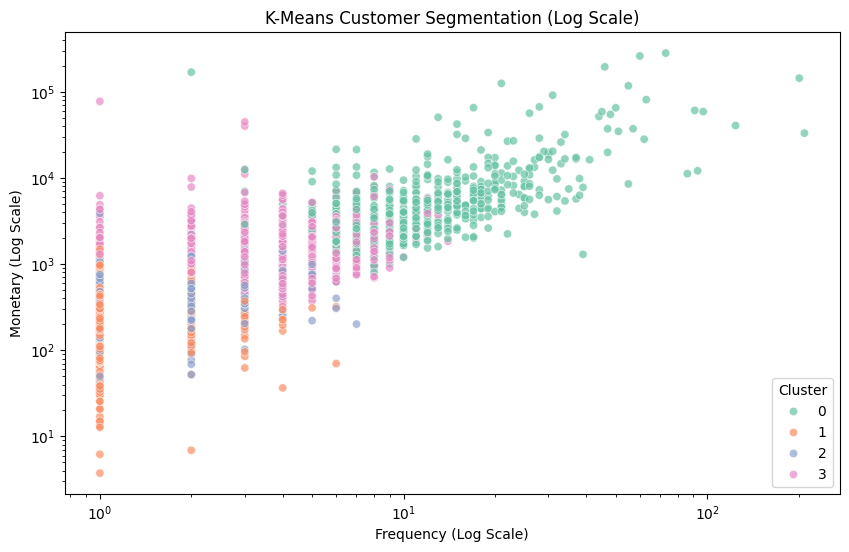

In [56]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=clustered_rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="Set2",
    alpha=0.7
)

plt.xscale("log")
plt.yscale("log")

plt.title("K-Means Customer Segmentation (Log Scale)")
plt.xlabel("Frequency (Log Scale)")
plt.ylabel("Monetary (Log Scale)")

plt.show()

**SILHOUETTE SCORE**

-1 TO +1 RANGE

In [57]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

In [58]:
score = silhouette_score(
    scaled_rfm,
    cluster_labels
)

print("Silhouette Score:", score)

Silhouette Score: 0.337517049212612


In [59]:
silhouette_scores = []

K_range = range(2, 11)

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    labels = kmeans.fit_predict(scaled_rfm)

    score = silhouette_score(
        scaled_rfm,
        labels
    )

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.4328
K = 3, Silhouette Score = 0.3365
K = 4, Silhouette Score = 0.3375
K = 5, Silhouette Score = 0.3162
K = 6, Silhouette Score = 0.3124
K = 7, Silhouette Score = 0.3092
K = 8, Silhouette Score = 0.3033
K = 9, Silhouette Score = 0.2811
K = 10, Silhouette Score = 0.2767


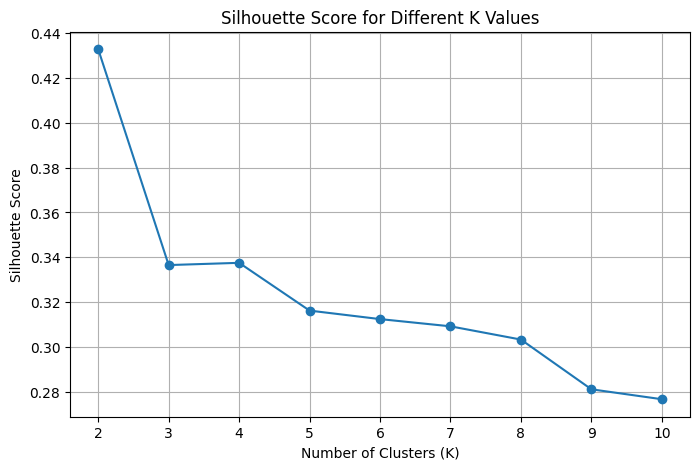

In [60]:
plt.figure(figsize=(8, 5))

plt.plot(
    K_range,
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")

plt.title("Silhouette Score for Different K Values")

plt.xticks(K_range)
plt.grid(True)

plt.show()

In [61]:
kmeans_export = rfm.loc[
    clustered_rfm.index,
    ["CustomerID"]
].join(
    clustered_rfm[[
        "Recency",
        "Frequency",
        "Monetary",
        "Cluster"
    ]]
)

kmeans_export.to_csv(
    "rfm_kmeans_results.csv",
    index=False
)

from google.colab import files
files.download("rfm_kmeans_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [62]:
for k in [2, 4]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(scaled_rfm)

    temp = rfm_features.loc[scaled_rfm.index].copy()
    temp["Cluster"] = labels

    print(f"\nCLUSTER SUMMARY FOR K = {k}")

    print(
        temp.groupby("Cluster").agg(
            Customers=("Recency", "count"),
            Avg_Recency=("Recency", "mean"),
            Avg_Frequency=("Frequency", "mean"),
            Avg_Monetary=("Monetary", "mean")
        ).round(2)
    )


CLUSTER SUMMARY FOR K = 2
         Customers  Avg_Recency  Avg_Frequency  Avg_Monetary
Cluster                                                     
0             2672       134.09           1.67        495.59
1             1666        25.89           8.44       4539.60

CLUSTER SUMMARY FOR K = 4
         Customers  Avg_Recency  Avg_Frequency  Avg_Monetary
Cluster                                                     
0              713        12.17          13.75       8088.02
1             1622       181.51           1.32        341.00
2              837        17.70           2.19        557.32
3             1166        71.64           4.08       1801.78


In [63]:
optimal_k = 4

final_kmeans = KMeans(
    n_clusters=optimal_k,
    init="k-means++",
    n_init=10,
    random_state=42
)

cluster_labels = final_kmeans.fit_predict(scaled_rfm)

clustered_rfm = rfm_features.loc[
    scaled_rfm.index
].copy()

clustered_rfm["Cluster"] = cluster_labels

In [65]:
kmeans_export = rfm.loc[
    clustered_rfm.index,
    ["CustomerID"]
].join(
    clustered_rfm[
        ["Recency", "Frequency", "Monetary", "Cluster"]
    ]
)

kmeans_export.to_csv(
    "rfm_kmeans_results.csv",
    index=False
)

from google.colab import files
files.download("rfm_kmeans_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>